
### Dataset: `tlast3.csv` | 162,567 rows × 11 columns

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Style
plt.rcParams.update({'figure.facecolor':'#0f0f0f','axes.facecolor':'#1a1a2e',
                     'axes.edgecolor':'#444','text.color':'white',
                     'axes.labelcolor':'white','xtick.color':'white',
                     'ytick.color':'white','grid.color':'#333',
                     'grid.linestyle':'--','font.size':11})
PALETTE = ['#e94560','#0f3460','#533483','#16213e','#e94560','#f5a623','#00d4ff','#7fff00','#ff6b6b','#ffd700']
sns.set_palette(PALETTE)

df = pd.read_csv('tlast3.csv')
df['date'] = pd.to_datetime(df['date'], dayfirst=True, errors='coerce')
df['hour'] = df['time_of_day'].str.split(':').str[0].astype(float)
df['month'] = df['date'].dt.month
df['year']  = df['date'].dt.year
df['festival_flag'] = df['festival'].notna().astype(int)

print('Shape:', df.shape)
df.head(3)

Shape: (162567, 15)


,date,source,destination,distance_km,congestion_index,time_of_day,weather,day_of_week,festival,actual_travel_time_min,road_type,hour,month,year,festival_flag
0,2022-07-15,Powai,Airoli,14.256019,0.293694,13:12,Cloudy,Friday,NaN,32.814877,urban,13.0,7.0,2022.0,0
1,2024-06-14,Dombivli,Mulund,17.796597,0.436896,09:11,Cloudy,Friday,NaN,58.923626,NaN,9.0,6.0,2024.0,0
2,2022-05-02,CST,Goregaon,37.720590,0.505821,02:17,Heavy Rain,Monday,Eid,114.466769,urban,2.0,5.0,2022.0,1


## 1 · Dataset Overview

In [2]:
print('=== DTYPES ===')
print(df.dtypes)
print('\n=== MISSING VALUES ===')
mv = df.isnull().sum()
print(mv[mv>0])
print('\n=== NUMERIC SUMMARY ===')
df.describe().round(2)

=== DTYPES ===
date                      datetime64[ns]
source                            object
destination                       object
distance_km                      float64
congestion_index                 float64
time_of_day                       object
weather                           object
day_of_week                       object
festival                          object
actual_travel_time_min           float64
road_type                         object
hour                             float64
month                            float64
year                             float64
festival_flag                      int64
dtype: object

=== MISSING VALUES ===
date                         282
source                       282
destination                  282
distance_km                 1932
congestion_index            1932
time_of_day                 2137
weather                     2229
day_of_week                  282
festival                  107810
actual_travel_time_min      1932
ro

,date,distance_km,congestion_index,actual_travel_time_min,hour,month,year,festival_flag
count,162285,160635.00,160635.00,160635.00,160430.00,162285.00,162285.00,162567.00
mean,2023-07-14 00:18:52.407801344,19.67,0.40,56.75,11.84,6.83,2023.01,0.34
min,2022-01-01 00:00:00,0.00,0.05,1.00,0.00,1.00,2022.00,0.00
25%,2022-10-13 00:00:00,10.19,0.30,26.75,6.00,4.00,2022.00,0.00
50%,2023-07-31 00:00:00,18.04,0.39,48.50,12.00,7.00,2023.00,0.00
75%,2024-04-11 00:00:00,26.99,0.48,77.20,18.00,10.00,2024.00,1.00
max,2024-12-31 00:00:00,59.71,0.87,300.00,23.00,12.00,2024.00,1.00
std,NaN,12.01,0.13,40.42,6.90,3.38,0.82,0.47


## 2 · Numeric Distributions (Histograms)

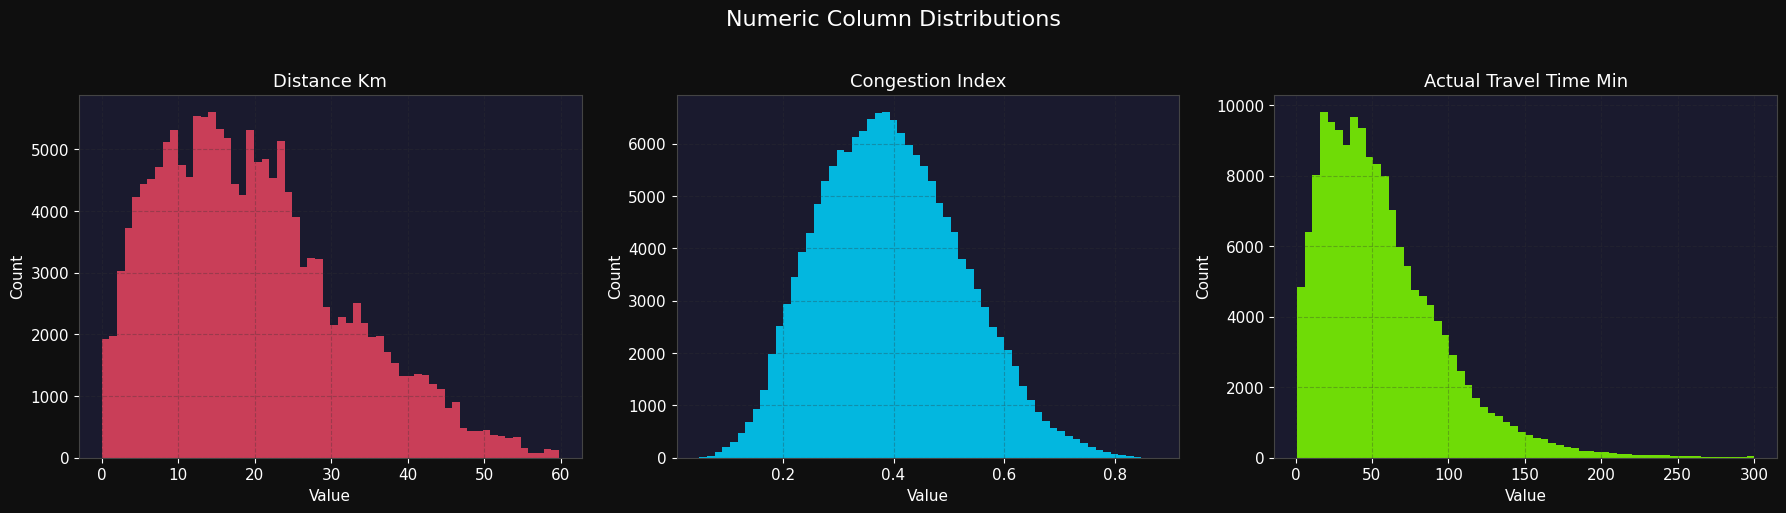

In [3]:
num_cols = ['distance_km','congestion_index','actual_travel_time_min']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Numeric Column Distributions', fontsize=16, color='white', y=1.02)
colors = ['#e94560','#00d4ff','#7fff00']
for ax, col, c in zip(axes, num_cols, colors):
    ax.hist(df[col].dropna(), bins=60, color=c, edgecolor='none', alpha=0.85)
    ax.set_title(col.replace('_',' ').title(), color='white', fontsize=13)
    ax.set_xlabel('Value'); ax.set_ylabel('Count')
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 3 · Weather — Record Count & Avg Travel Time

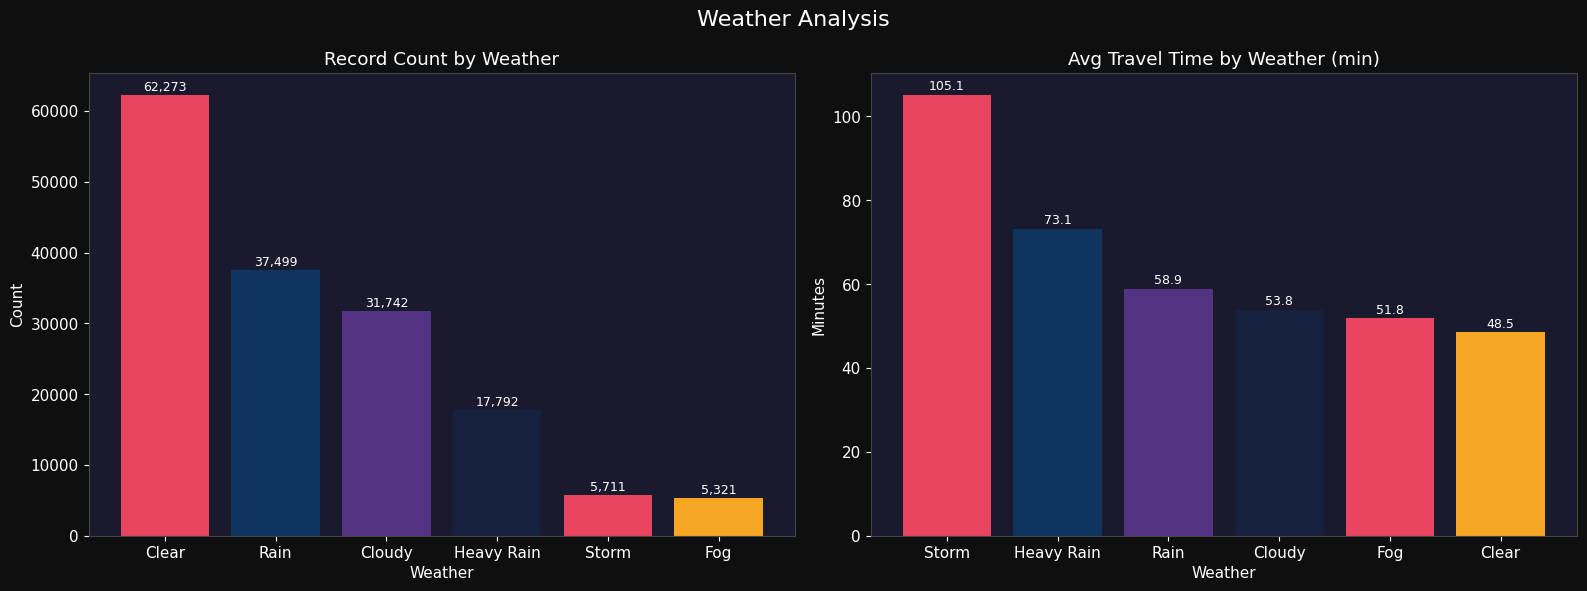

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Weather Analysis', fontsize=16, color='white')

wc = df['weather'].value_counts()
bars = axes[0].bar(wc.index, wc.values, color=PALETTE[:len(wc)], edgecolor='none')
axes[0].set_title('Record Count by Weather', color='white')
axes[0].set_xlabel('Weather'); axes[0].set_ylabel('Count')
for b in bars:
    axes[0].text(b.get_x()+b.get_width()/2, b.get_height()+200, f'{int(b.get_height()):,}',
                 ha='center', va='bottom', color='white', fontsize=9)

wa = df.groupby('weather')['actual_travel_time_min'].mean().sort_values(ascending=False)
bars2 = axes[1].bar(wa.index, wa.values, color=PALETTE[:len(wa)], edgecolor='none')
axes[1].set_title('Avg Travel Time by Weather (min)', color='white')
axes[1].set_xlabel('Weather'); axes[1].set_ylabel('Minutes')
for b in bars2:
    axes[1].text(b.get_x()+b.get_width()/2, b.get_height()+0.5, f'{b.get_height():.1f}',
                 ha='center', va='bottom', color='white', fontsize=9)
plt.tight_layout()
plt.show()

## 4 · Day of Week Analysis

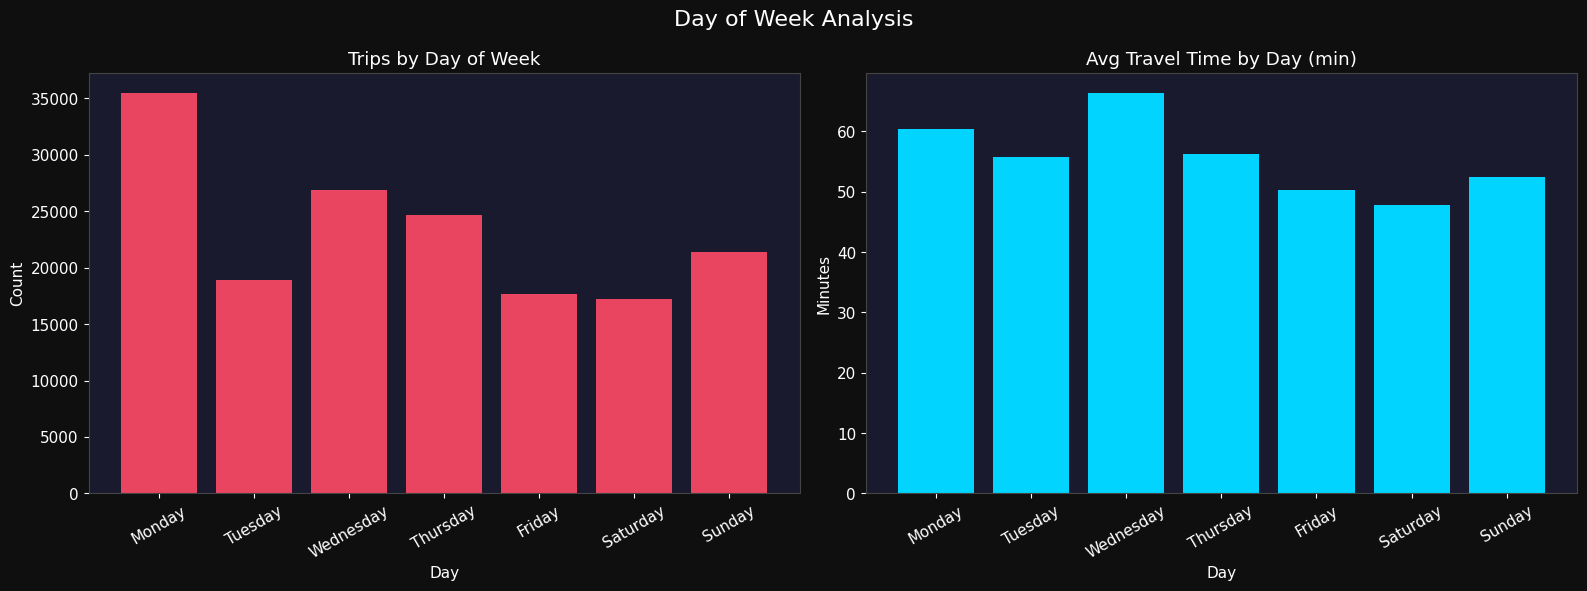

In [5]:
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Day of Week Analysis', fontsize=16, color='white')

dc = df['day_of_week'].value_counts().reindex(order)
axes[0].bar(dc.index, dc.values, color='#e94560', edgecolor='none')
axes[0].set_title('Trips by Day of Week', color='white')
axes[0].set_xlabel('Day'); axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=30)

da = df.groupby('day_of_week')['actual_travel_time_min'].mean().reindex(order)
axes[1].bar(da.index, da.values, color='#00d4ff', edgecolor='none')
axes[1].set_title('Avg Travel Time by Day (min)', color='white')
axes[1].set_xlabel('Day'); axes[1].set_ylabel('Minutes')
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

## 5 · Road Type Analysis

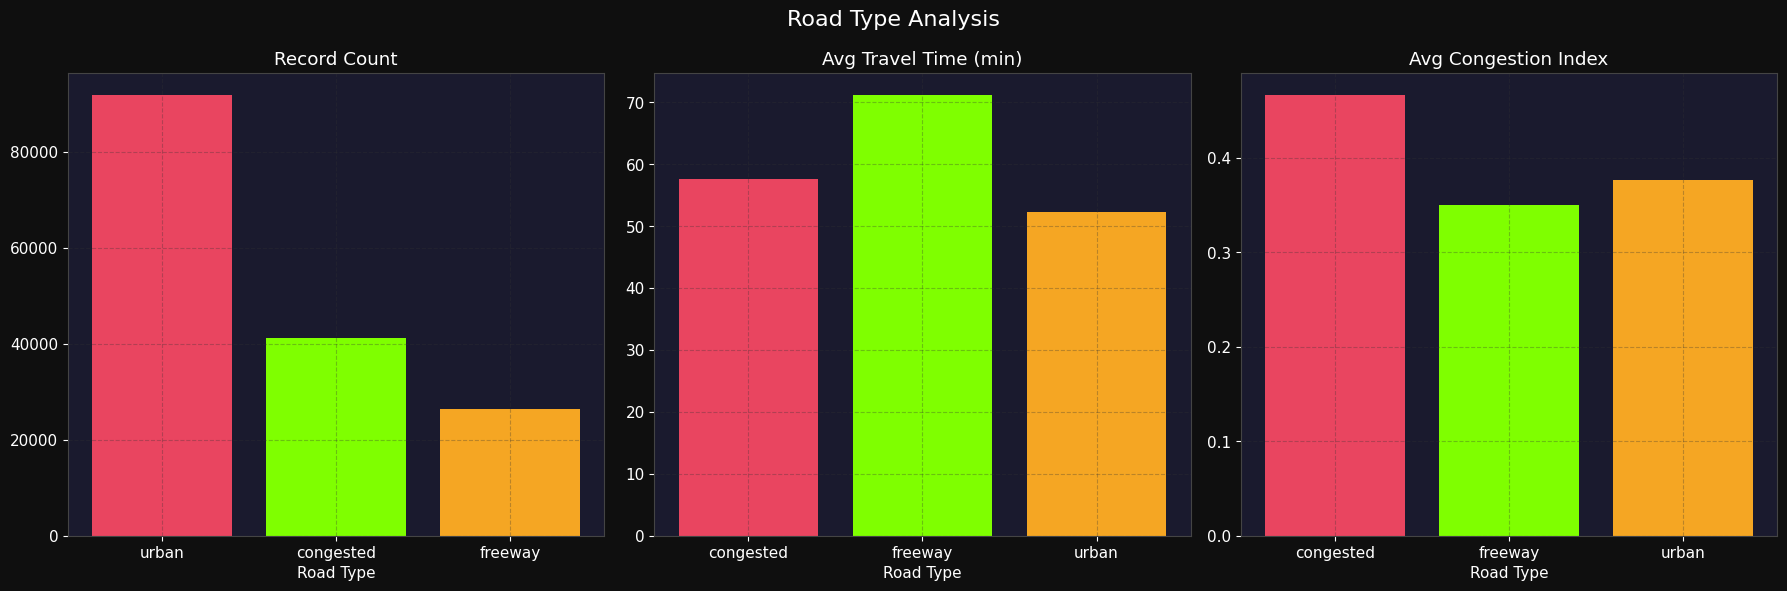

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Road Type Analysis', fontsize=16, color='white')

rc = df['road_type'].value_counts()
axes[0].bar(rc.index, rc.values, color=['#e94560','#7fff00','#f5a623'], edgecolor='none')
axes[0].set_title('Record Count', color='white')

ra = df.groupby('road_type')['actual_travel_time_min'].mean()
axes[1].bar(ra.index, ra.values, color=['#e94560','#7fff00','#f5a623'], edgecolor='none')
axes[1].set_title('Avg Travel Time (min)', color='white')

rci = df.groupby('road_type')['congestion_index'].mean()
axes[2].bar(rci.index, rci.values, color=['#e94560','#7fff00','#f5a623'], edgecolor='none')
axes[2].set_title('Avg Congestion Index', color='white')

for ax in axes:
    ax.set_xlabel('Road Type'); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6 · Festival Impact

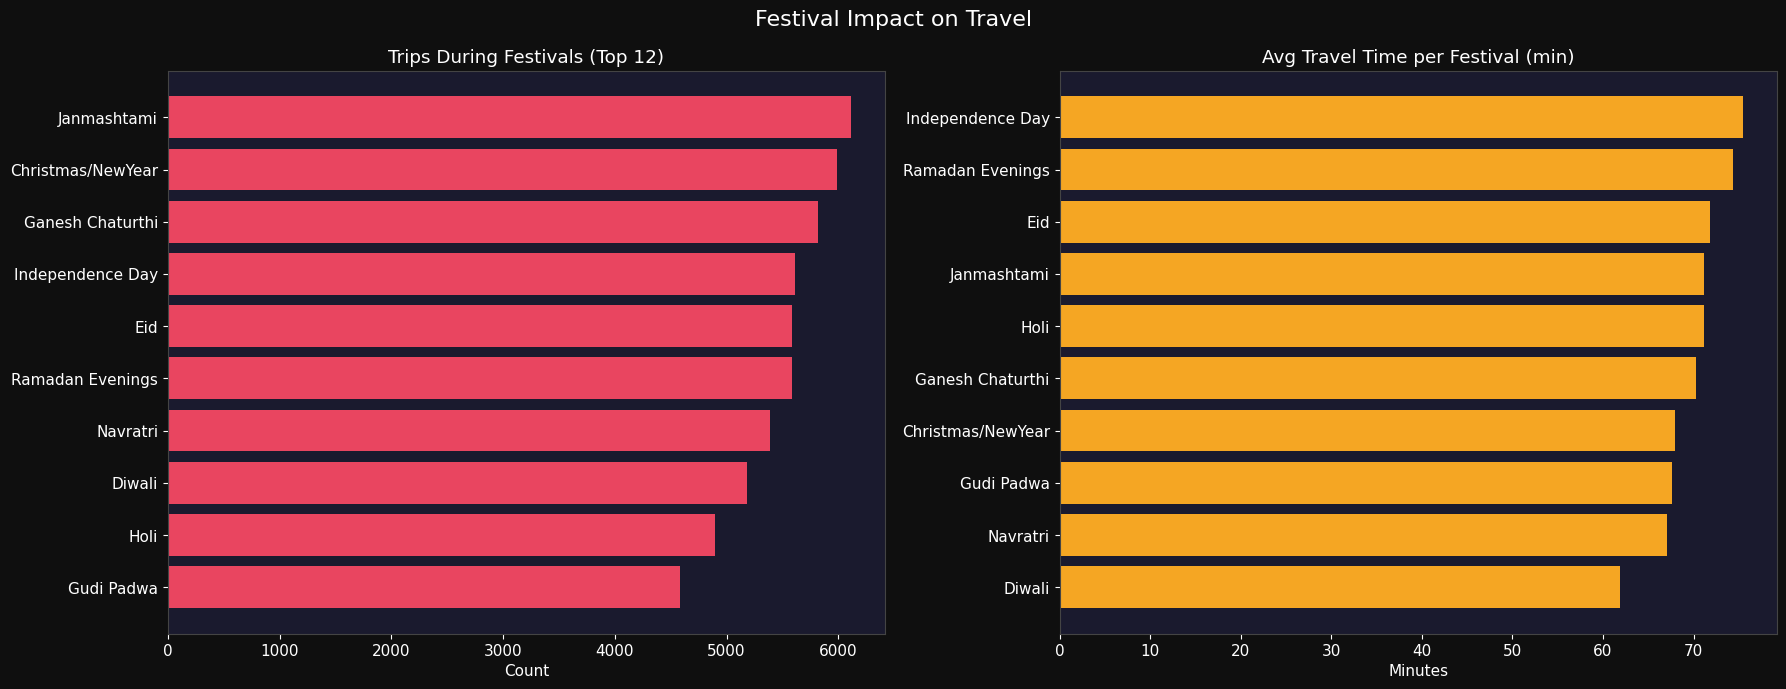

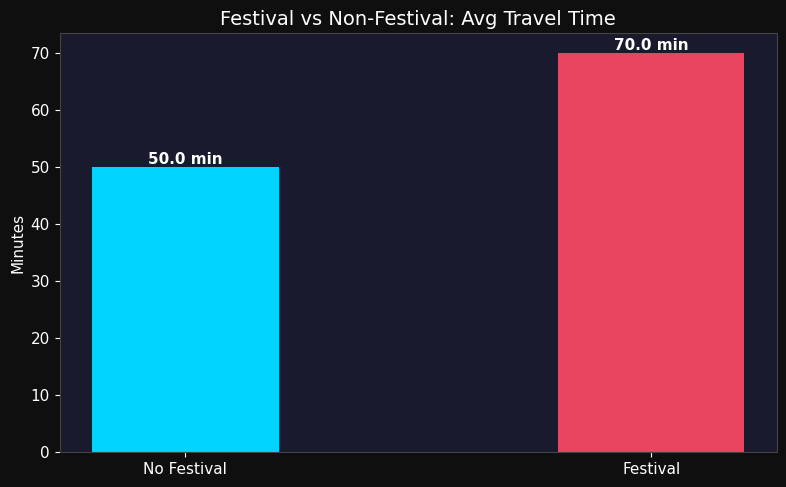

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Festival Impact on Travel', fontsize=16, color='white')

# Top festivals by count
fc = df['festival'].value_counts().head(12)
axes[0].barh(fc.index, fc.values, color='#e94560', edgecolor='none')
axes[0].set_title('Trips During Festivals (Top 12)', color='white')
axes[0].invert_yaxis()
axes[0].set_xlabel('Count')

# Festival vs no-festival travel time
fa = df.groupby('festival')['actual_travel_time_min'].mean().sort_values(ascending=False).head(12)
axes[1].barh(fa.index, fa.values, color='#f5a623', edgecolor='none')
axes[1].set_title('Avg Travel Time per Festival (min)', color='white')
axes[1].invert_yaxis()
axes[1].set_xlabel('Minutes')

plt.tight_layout()
plt.show()

# Festival vs Non-Festival
fig2, ax = plt.subplots(figsize=(8,5))
fcomp = df.groupby('festival_flag')['actual_travel_time_min'].mean()
ax.bar(['No Festival','Festival'], fcomp.values, color=['#00d4ff','#e94560'], width=0.4, edgecolor='none')
ax.set_title('Festival vs Non-Festival: Avg Travel Time', color='white', fontsize=14)
ax.set_ylabel('Minutes')
for i, v in enumerate(fcomp.values):
    ax.text(i, v+0.5, f'{v:.1f} min', ha='center', color='white', fontweight='bold')
plt.tight_layout()
plt.show()

## 7 · Hour of Day — Travel Pattern

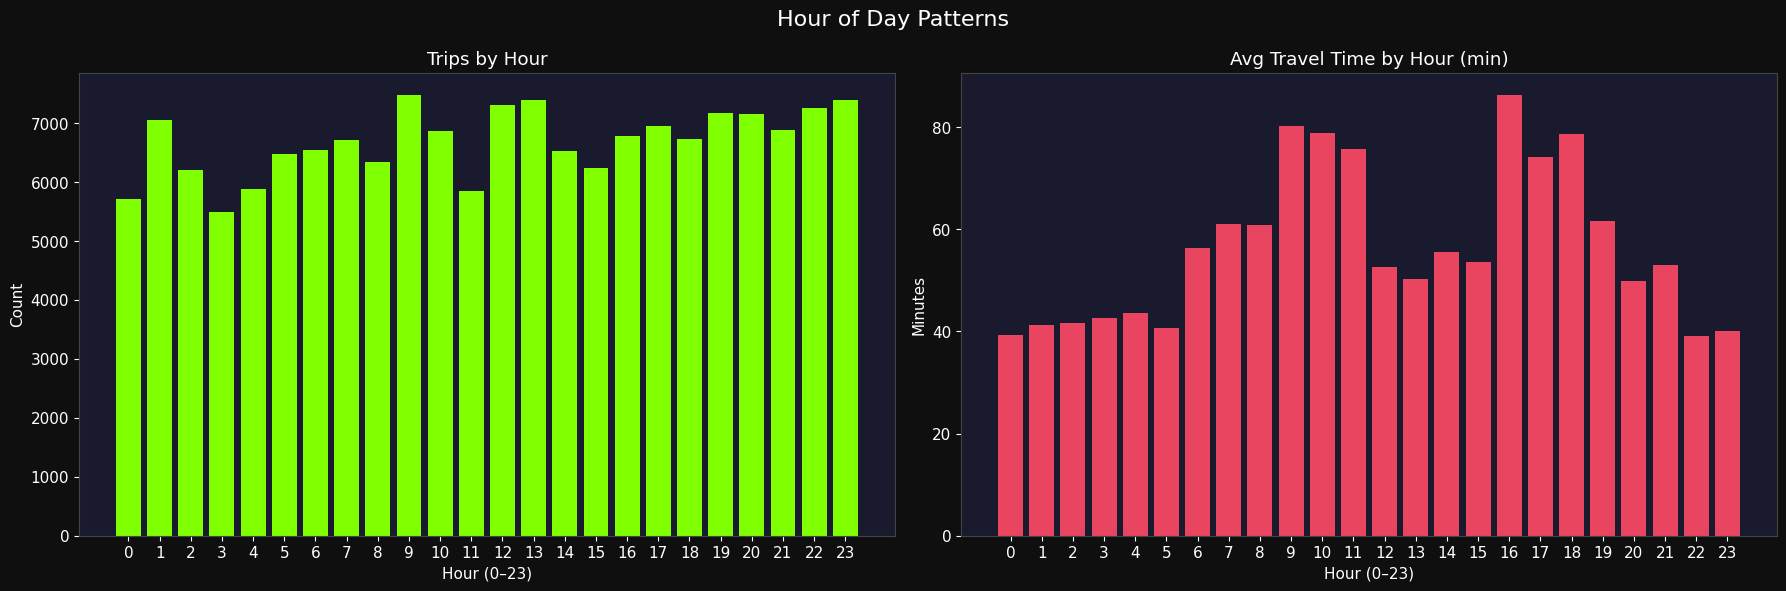

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Hour of Day Patterns', fontsize=16, color='white')

hc = df.groupby('hour').size()
axes[0].bar(hc.index, hc.values, color='#7fff00', edgecolor='none', width=0.8)
axes[0].set_title('Trips by Hour', color='white')
axes[0].set_xlabel('Hour (0–23)'); axes[0].set_ylabel('Count')
axes[0].set_xticks(range(0,24))

ha = df.groupby('hour')['actual_travel_time_min'].mean()
axes[1].bar(ha.index, ha.values, color='#e94560', edgecolor='none', width=0.8)
axes[1].set_title('Avg Travel Time by Hour (min)', color='white')
axes[1].set_xlabel('Hour (0–23)'); axes[1].set_ylabel('Minutes')
axes[1].set_xticks(range(0,24))
plt.tight_layout()
plt.show()

## 8 · Top 10 Sources & Destinations

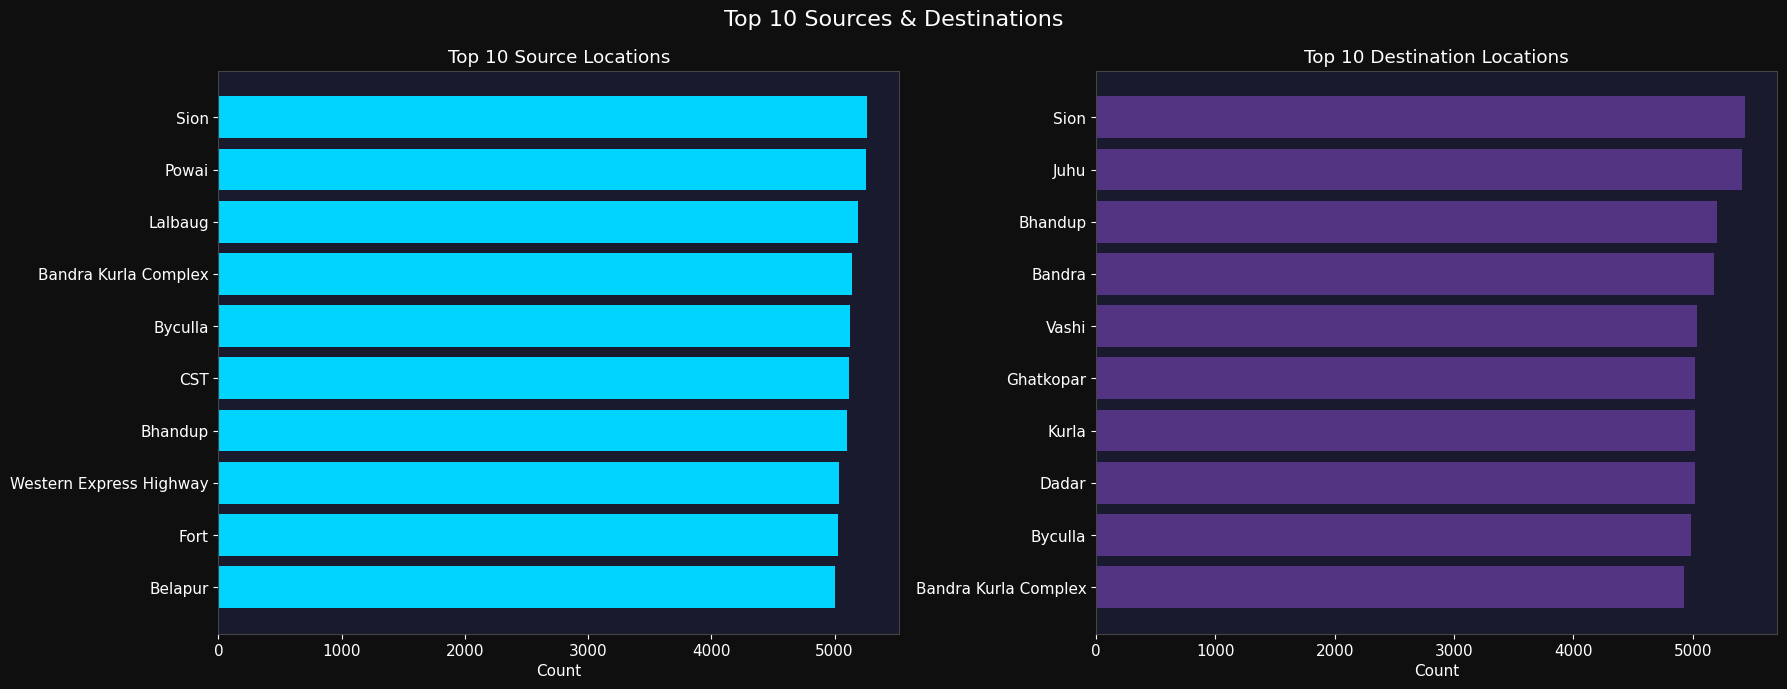

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Top 10 Sources & Destinations', fontsize=16, color='white')

sc = df['source'].value_counts().head(10)
axes[0].barh(sc.index, sc.values, color='#00d4ff', edgecolor='none')
axes[0].set_title('Top 10 Source Locations', color='white')
axes[0].invert_yaxis(); axes[0].set_xlabel('Count')

dc = df['destination'].value_counts().head(10)
axes[1].barh(dc.index, dc.values, color='#533483', edgecolor='none')
axes[1].set_title('Top 10 Destination Locations', color='white')
axes[1].invert_yaxis(); axes[1].set_xlabel('Count')
plt.tight_layout()
plt.show()

## 9 · Congestion Index Deep Dive

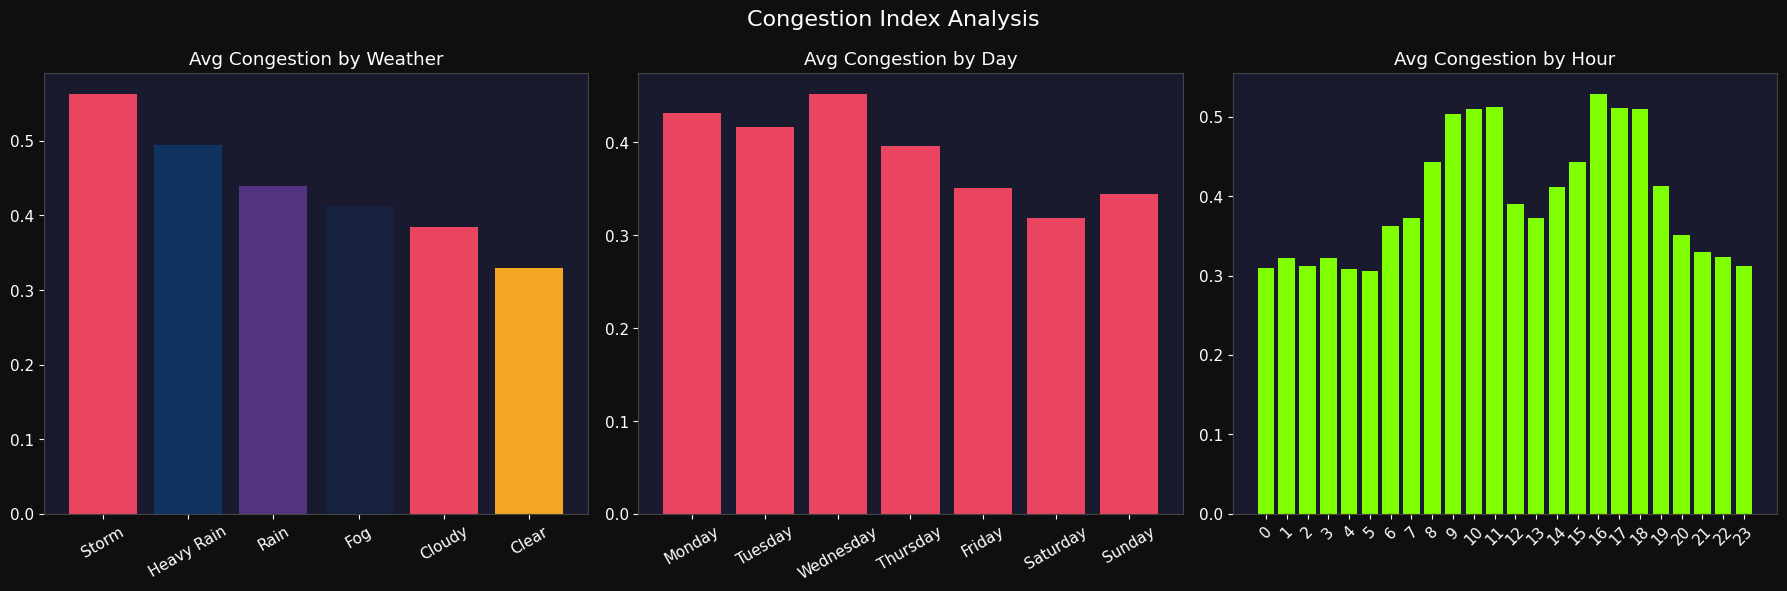

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Congestion Index Analysis', fontsize=16, color='white')

# By weather
cw = df.groupby('weather')['congestion_index'].mean().sort_values(ascending=False)
axes[0].bar(cw.index, cw.values, color=PALETTE[:len(cw)], edgecolor='none')
axes[0].set_title('Avg Congestion by Weather', color='white')
axes[0].tick_params(axis='x', rotation=30)

# By day
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
cd = df.groupby('day_of_week')['congestion_index'].mean().reindex(order)
axes[1].bar(cd.index, cd.values, color='#e94560', edgecolor='none')
axes[1].set_title('Avg Congestion by Day', color='white')
axes[1].tick_params(axis='x', rotation=30)

# By hour
ch = df.groupby('hour')['congestion_index'].mean()
axes[2].bar(ch.index, ch.values, color='#7fff00', edgecolor='none', width=0.8)
axes[2].set_title('Avg Congestion by Hour', color='white')
axes[2].set_xticks(range(0,24))
axes[2].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

## 10 · Year & Month Trends

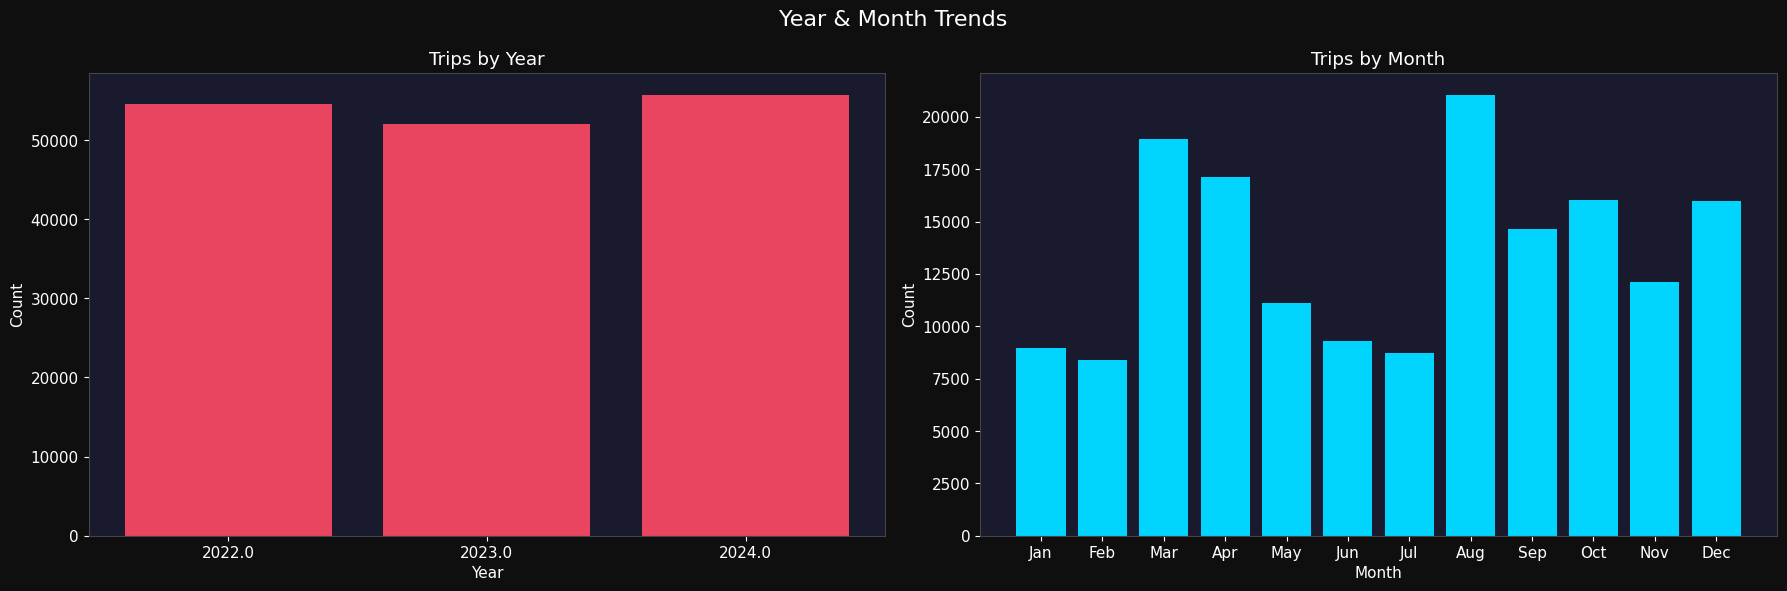

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Year & Month Trends', fontsize=16, color='white')

yc = df.groupby('year').size()
axes[0].bar(yc.index.astype(str), yc.values, color='#e94560', edgecolor='none')
axes[0].set_title('Trips by Year', color='white')
axes[0].set_xlabel('Year'); axes[0].set_ylabel('Count')

mc = df.groupby('month').size()
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
axes[1].bar(month_names, [mc.get(i,0) for i in range(1,13)], color='#00d4ff', edgecolor='none')
axes[1].set_title('Trips by Month', color='white')
axes[1].set_xlabel('Month'); axes[1].set_ylabel('Count')
plt.tight_layout()
plt.show()

## 11 · Correlation Heatmap

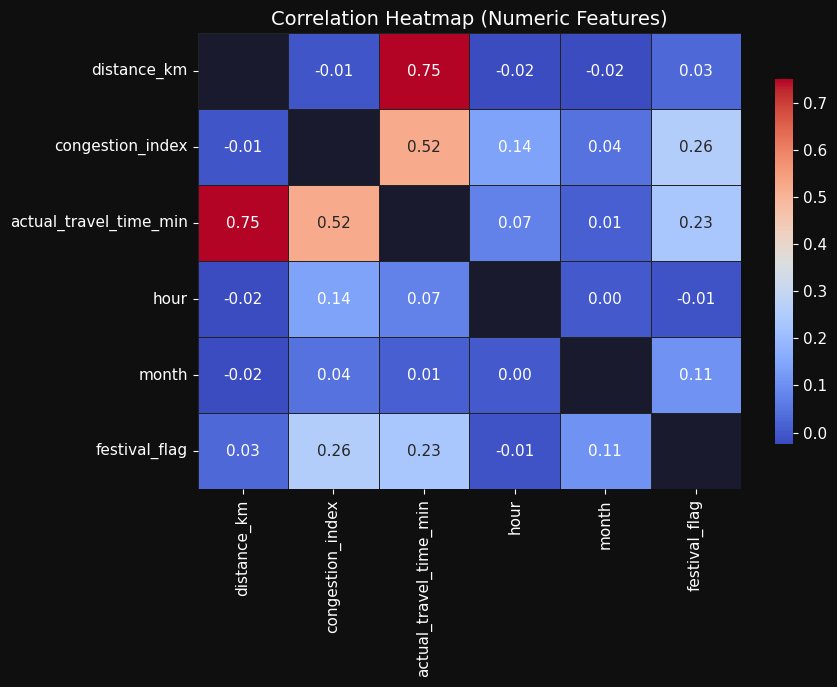

In [12]:
num_df = df[['distance_km','congestion_index','actual_travel_time_min','hour','month','festival_flag']].dropna()
corr = num_df.corr()

fig, ax = plt.subplots(figsize=(9, 7))
mask = np.zeros_like(corr, dtype=bool)
np.fill_diagonal(mask, True)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=ax,
            linewidths=0.5, linecolor='#222', mask=mask,
            cbar_kws={'shrink':0.8})
ax.set_title('Correlation Heatmap (Numeric Features)', color='white', fontsize=14)
ax.tick_params(colors='white')
plt.tight_layout()
plt.show()

## 12 · Multi-Comparison: Weather × Road Type × Travel Time

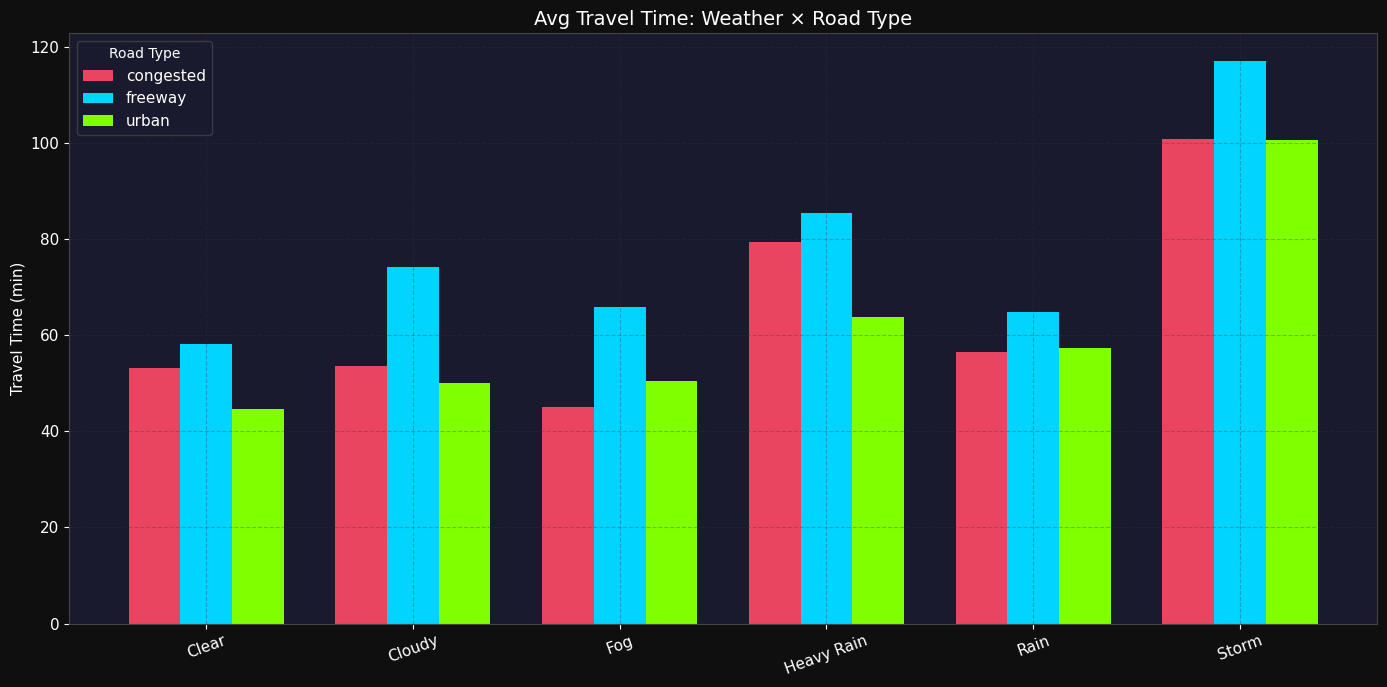

In [13]:
pivot = df.groupby(['weather','road_type'])['actual_travel_time_min'].mean().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(14, 7))
x = np.arange(len(pivot.index))
w = 0.25
colors = ['#e94560','#00d4ff','#7fff00']
for i, (col, c) in enumerate(zip(pivot.columns, colors)):
    ax.bar(x + i*w, pivot[col], width=w, label=col, color=c, edgecolor='none')

ax.set_xticks(x + w)
ax.set_xticklabels(pivot.index, rotation=20)
ax.set_title('Avg Travel Time: Weather × Road Type', color='white', fontsize=14)
ax.set_ylabel('Travel Time (min)')
ax.legend(title='Road Type', title_fontsize=10, labelcolor='white',
          facecolor='#1a1a2e', edgecolor='#444')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 13 · Distance vs Travel Time (Scatter by Road Type)

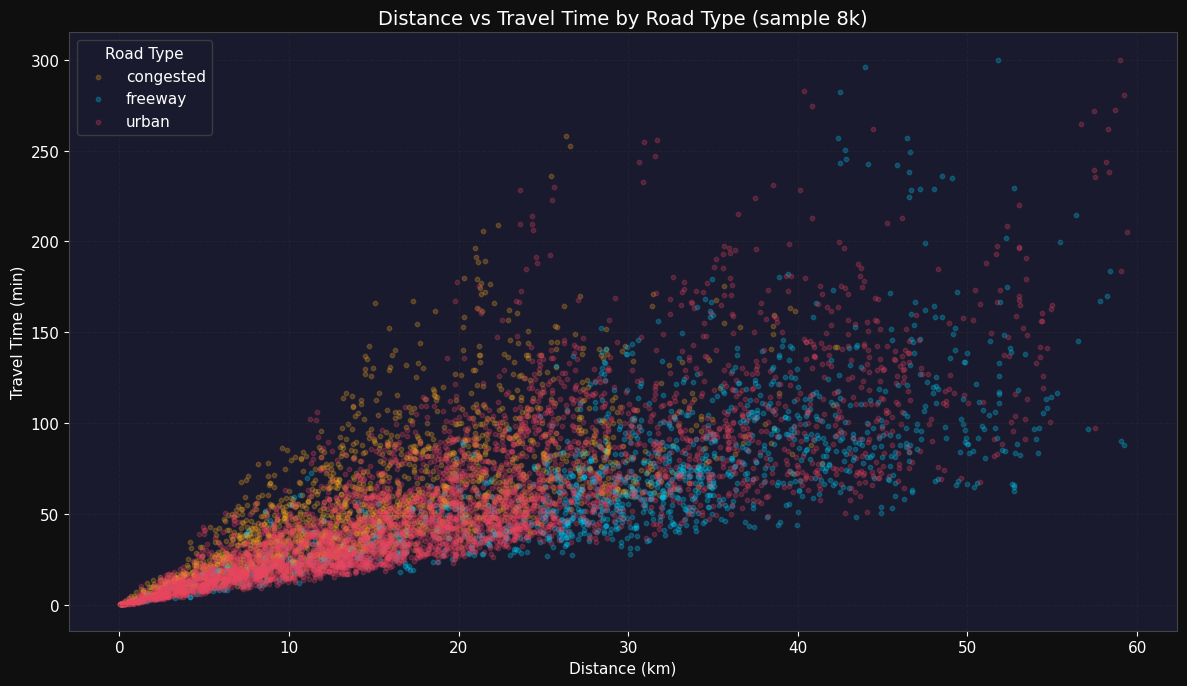

In [14]:
fig, ax = plt.subplots(figsize=(12, 7))
sample = df.dropna(subset=['road_type']).sample(8000, random_state=42)
colors = {'urban':'#e94560','congested':'#f5a623','freeway':'#00d4ff'}
for rt, grp in sample.groupby('road_type'):
    ax.scatter(grp['distance_km'], grp['actual_travel_time_min'],
               alpha=0.25, s=10, color=colors.get(rt,'white'), label=rt)
ax.set_xlabel('Distance (km)')
ax.set_ylabel('Travel Time (min)')
ax.set_title('Distance vs Travel Time by Road Type (sample 8k)', color='white', fontsize=14)
ax.legend(title='Road Type', facecolor='#1a1a2e', edgecolor='#444', labelcolor='white')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 14 · Boxplots: Travel Time Distribution

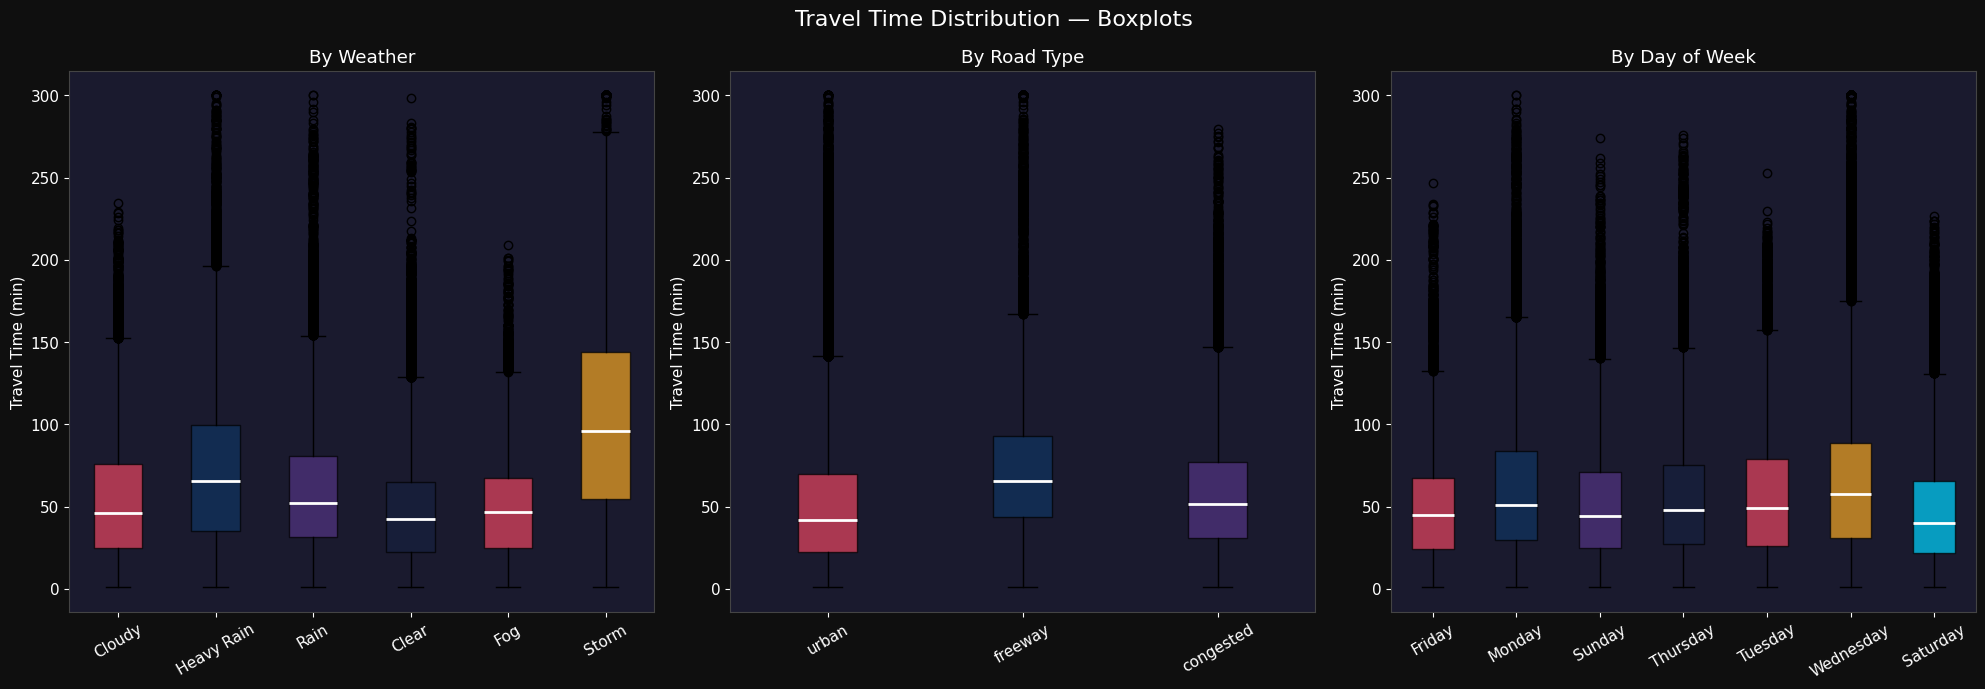

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
fig.suptitle('Travel Time Distribution — Boxplots', fontsize=16, color='white')

for ax, col, title in zip(axes,
    ['weather','road_type','day_of_week'],
    ['By Weather','By Road Type','By Day of Week']):
    data = [df[df[col]==c]['actual_travel_time_min'].dropna().values for c in df[col].dropna().unique()]
    labels = df[col].dropna().unique()
    bp = ax.boxplot(data, patch_artist=True, labels=labels, medianprops=dict(color='white',linewidth=2))
    for patch, color in zip(bp['boxes'], PALETTE):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    ax.set_title(title, color='white')
    ax.set_ylabel('Travel Time (min)')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

## 15 · Summary Insights

In [16]:
print('='*60)
print('KEY INSIGHTS')
print('='*60)
print(f"Total records        : {len(df):,}")
print(f"Date range           : {df['date'].min().date()} → {df['date'].max().date()}")
print(f"Avg distance         : {df['distance_km'].mean():.1f} km")
print(f"Avg travel time      : {df['actual_travel_time_min'].mean():.1f} min")
print(f"Avg congestion index : {df['congestion_index'].mean():.3f}")
print()
print('Worst weather (travel time):', df.groupby('weather')['actual_travel_time_min'].mean().idxmax())
print('Worst day (travel time)    :', df.groupby('day_of_week')['actual_travel_time_min'].mean().idxmax())
print('Worst road type            :', df.groupby('road_type')['actual_travel_time_min'].mean().idxmax())
print('Festival w/ most trips     :', df['festival'].value_counts().idxmax())
peak_hr = df.groupby('hour')['actual_travel_time_min'].mean().idxmax()
print(f'Peak congestion hour       : {int(peak_hr):02d}:00')

KEY INSIGHTS
Total records        : 162,567
Date range           : 2022-01-01 → 2024-12-31
Avg distance         : 19.7 km
Avg travel time      : 56.7 min
Avg congestion index : 0.396

Worst weather (travel time): Storm
Worst day (travel time)    : Wednesday
Worst road type            : freeway
Festival w/ most trips     : Janmashtami
Peak congestion hour       : 16:00
